# Action representations, step by step 🎯
### How a vision-language-action model *writes* its actions: tokens, flows, diffusion and chunks

**Code:** `src/Halo_VLA/vla_foundations/` (`discretization.py`, `autoregressive.py`, `diffusion.py`, `toy2d.py`, `chunking.py`, `multimodality.py`) on top of `open_vlas` and `pi_family` ·
**papers:** RT-2 ([arXiv:2307.15818](https://arxiv.org/abs/2307.15818)), OpenVLA ([2406.09246](https://arxiv.org/abs/2406.09246)), Diffusion Policy ([2303.04137](https://arxiv.org/abs/2303.04137)),
Flow Matching ([2210.02747](https://arxiv.org/abs/2210.02747)), π0 ([2410.24164](https://arxiv.org/abs/2410.24164)), ACT ([2304.13705](https://arxiv.org/abs/2304.13705)), SmolVLA ([2506.01844](https://arxiv.org/abs/2506.01844)).

A VLM reads an image and a sentence and produces *features*. A robot needs **numbers**: a few-dimensional continuous command, many times per second. The **action representation** is the bridge, and it is
one of the most consequential design choices in a VLA. This notebook builds the four ideas the field converged on, in the same toy world, so that you can *measure* what each one costs and buys:

| part | idea | the question it answers |
|---|---|---|
| 1 | **discrete tokenisation** (RT-2, OpenVLA): bin every action dimension, emit the bins as text tokens | why is it slow? why is it lossy? how do the bins work? |
| 2 | **flow matching** vs **DDPM diffusion** (π0, GR00T, SmolVLA vs Diffusion Policy): learn a vector field that carries noise to actions | why does it handle several valid solutions? how many network calls does it need? |
| 3 | **Diffusion Policy**: DDPM chains, DDIM shortcuts | what exactly is different from flow matching, in the policy? |
| 4 | **chunked prediction** (ACT, π0.5, SmolVLA): predict `H` actions per call | does it reduce compounding error? what does it do to the control rate? |

### Where this notebook corrects the usual summary
A few things in common study notes do not match the papers; the notebook follows the papers:

* RT-2's actions are **end-effector deltas** (6-DoF position/rotation, gripper, plus a terminate flag: *8 integers per step*), not joint values; each is one of **256 uniform bins**.
* The "~5 Hz" belongs to the **5B** RT-2-PaLI-X; the **55B** model runs at **1-3 Hz**. OpenVLA (7B) runs at ~6 Hz on an RTX 4090. RT-2 predicts *one step at a time*, with no chunk.
* "Flow matching = straight paths" is about the **training pairs**: the conditional path from one noise sample to one action is a line, but the *learned* field averages over all pairs through a point, so sampled paths are
  curved where the data has several modes (Step 6 measures this). The speed advantage is real but smaller and more nuanced than the slogan.

| | published | this notebook |
|---|---|---|
| action | RT-2: 256 bins × 8 integers; π0: 50-step chunks of continuous actions | 2-D end-effector displacement; chunk of 16 |
| VLM | PaLI-X 5B / 55B, Llama 2 7B, PaliGemma 3B | toy VLM, 6 layers, pre-trained on VQA |
| flow / diffusion | π0: 10 Euler steps; Diffusion Policy: DDPM 100 train steps, DDIM 10 inference steps | the same step counts |
| evaluation | real robots, LIBERO | closed loop in a 2-D point world |

> One seed, 96 scenes per number: read gaps of a few points as noise, large effects as real. Total runtime is about 35 minutes on a laptop CPU.

## Step 0: Setup, the world, and the shared VLM

The point world of the earlier notebooks: a 32×32 image with a robot dot and 2-3 coloured squares, an instruction, and a 2-D action (the end-effector displacement, `|a| ≈ 1` = one full step of 0.05).
Two tasks matter here:

* **`go to <colour>`**: one correct answer (*unimodal* demonstrations);
* **`go to any`**: two objects are equally good and the demonstrator picks one at random (*multimodal* demonstrations).

All policies share one **pre-trained VLM** (stage 0: visual question answering) so that differences come from the action representation, not from perception. Its vocabulary has 256 spare "action token" slots,
used only by the discrete-token policy.

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import fnd_kit
fnd_kit.setup_paths()
from fnd_kit import plots, diagrams as dg
from vla_kit import plots as vplots

from open_vlas import (EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, SmolVLAConfig, SmolVLAPolicy, ToyVLM, VLMConfig, VLMPretrainer,
                       make_embodied_scenarios, make_reach_demos)
from pi_family import PiTrainer, PiVocabulary
from pi_family.toy import DemoGenerator, PointWorld
from vla_foundations.autoregressive import ARConfig, AutoregressiveActionPolicy
from vla_foundations.chunking import ChunkedRunner, effective_control_hz
from vla_foundations.diffusion import DDPMSchedule, DiffusionPolicy
from vla_foundations.discretization import ActionBinner
from vla_foundations.multimodality import mode_coverage, separated_any_scenarios
from vla_foundations import toy2d

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world = PointWorld()
gen = DemoGenerator(world)
reach_demos = make_reach_demos(gen, 4000, np.random.default_rng(0))
any_demos = [gen.demo("any", np.random.default_rng(100 + i)) for i in range(4000)]
print(f"{len(reach_demos)} 'go to <colour>' demos, {len(any_demos)} 'go to any' demos; mean length {np.mean([e.active_steps for e in reach_demos]):.1f} steps")

4000 'go to <colour>' demos, 4000 'go to any' demos; mean length 11.6 steps


VLM pre-training 127 s, answer-token accuracy 0.93; vocabulary 310 ids (256 reserved for actions)


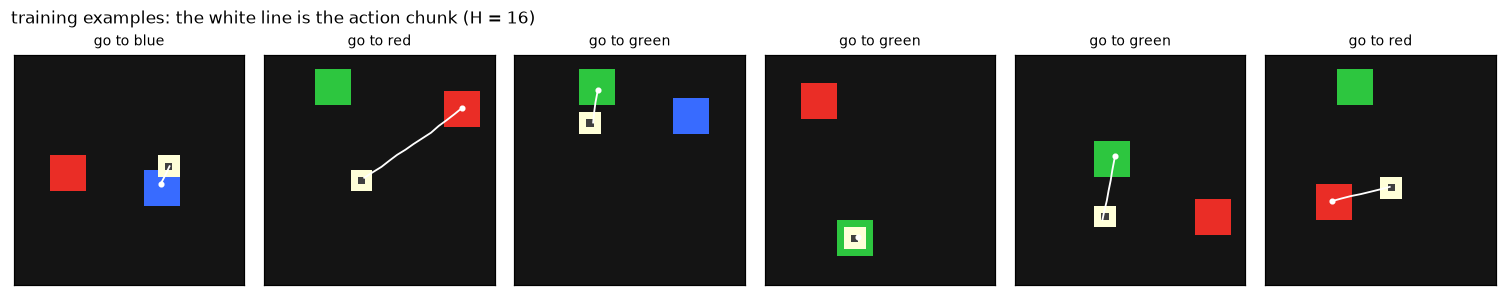

In [2]:
vocab = PiVocabulary(fast_size=256)                    # 256 extra token ids: the action-token slots
vlm = ToyVLM(VLMConfig(), vocab)
pre = VLMPretrainer(vlm, world)
pre.fit(1500)
print(f"VLM pre-training {pre.history.seconds:.0f} s, answer-token accuracy {np.mean(pre.history.accuracy[-50:]):.2f}; vocabulary {vocab.size} ids ({vocab.fast_size} reserved for actions)")

reach = EmbodiedMixture([EmbodiedSource(world, reach_demos, EMBODIMENTS["point2d"], chunk_size=16)])
any_ = EmbodiedMixture([EmbodiedSource(world, any_demos, EMBODIMENTS["point2d"], chunk_size=16)])
ev = EmbodiedEvaluator(world, 16, 8, 50)
reach_scen = make_embodied_scenarios(gen, "point2d", 96, seed=123)
any_scen = separated_any_scenarios(world, 96, seed=321)      # two objects ≥ 60° apart as seen from the robot: the *average* of the two modes cannot hit either
batch = reach.sample(6, np.random.default_rng(1))
vplots.show_batch(batch, title="training examples: the white line is the action chunk (H = 16)")

### 🖼️ Diagram: four ways to emit actions

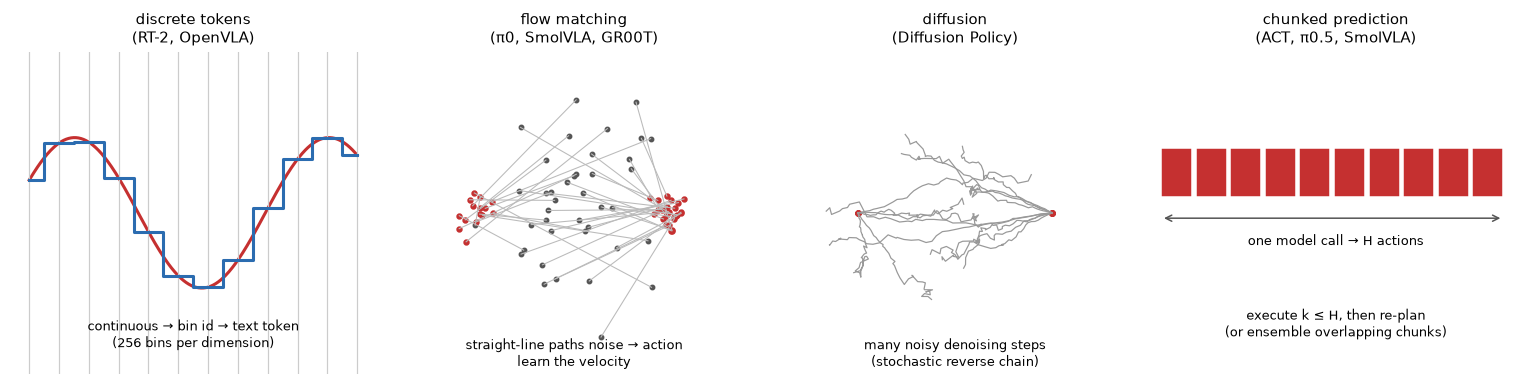

In [3]:
dg.fig_action_heads_overview()

# Part 1: Discrete tokenisation (RT-2, OpenVLA)

## Step 1: Binning, and the sequence the VLM writes

**RT-2** turns a VLM into a policy with one trick: *"express the actions as text tokens and incorporate them directly into the training set of the model in the same way as natural language tokens"*.
Concretely each continuous action dimension is **uniformly discretised into 256 bins**, the 256 bin ids are mapped to 256 reserved vocabulary tokens, and an action becomes a short string, e.g.
`"1 128 124 136 121 158 111 255"` (8 integers: terminate, Δposition ×3, Δrotation ×3, gripper). Training is the VLM's ordinary next-token cross-entropy; at inference the tokens are decoded and mapped back to bin centres.
Nothing about the VLM architecture changes, which is the whole appeal: the web-pre-trained weights are used as they are.

**OpenVLA** keeps the 256 bins but sets each dimension's range to the **1st-99th percentile** of the training actions instead of the min-max, "to ignore outlier actions … that could otherwise drastically expand the discretization interval".

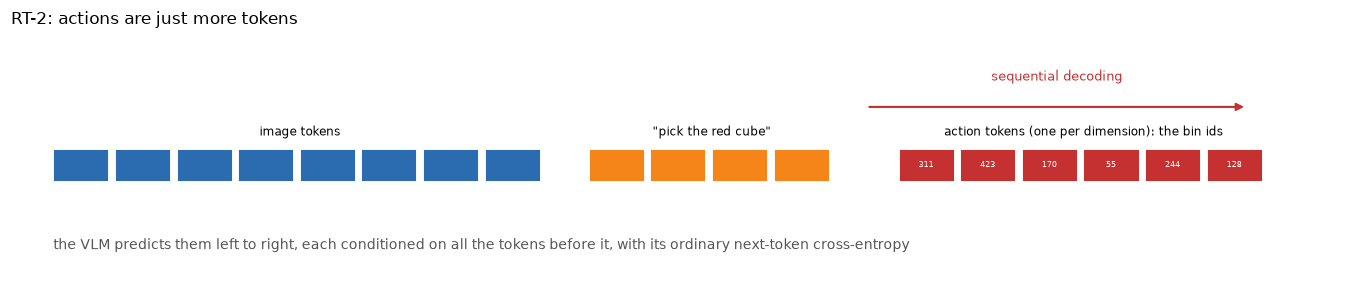

continuous actions (dx, dy):
 [[-0.711 -0.619]
 [-0.325  0.813]
 [-0.755  0.365]
 [-0.723 -0.595]]
→ bin ids (0..255):
 [[ 67  75]
 [100 197]
 [ 63 159]
 [ 66  77]]
→ decoded (bin centres):
 [[-0.709 -0.615]
 [-0.322  0.814]
 [-0.756  0.369]
 [-0.721 -0.592]]
bin width 0.0117 → the largest possible error per dimension is half of that: 0.0059


In [4]:
dg.fig_rt2_sequence()
binner = ActionBinner(256, -1.5, 1.5)
a = np.stack([e.actions[3] for e in reach_demos[:4]])
bins = binner.encode(a)
print("continuous actions (dx, dy):\n", a.round(3))
print("→ bin ids (0..255):\n", bins.numpy())
print("→ decoded (bin centres):\n", binner.decode(bins).numpy().round(3))
print(f"bin width {binner.bin_width[0] if binner.bin_width.ndim else binner.bin_width:.4f} → the largest possible error per dimension is half of that: {binner.max_error():.4f}")

## Step 2: How lossy is it? Resolution, outliers and quantiles

A bin is `(high − low)/num_bins` wide, so decoding returns the bin *centre*: the error is uniform in ±half a bin, with RMS `width/√12`. We measure it on real demonstration actions for several resolutions, and then
show what OpenVLA's quantile rule fixes when a few sensor-glitch outliers sit in the data.

/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_73413/473846820.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rmse = [float(np.sqrt(((ActionBinner(n, -1.5, 1.5).roundtrip(acts) - torch.from_numpy(acts)) ** 2).mean())) for n in nbs]


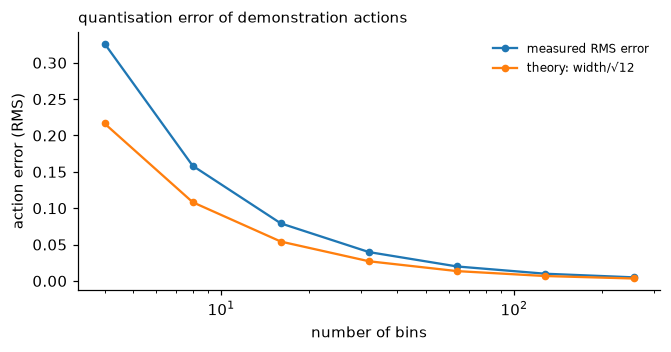

min-max range                    bin width 0.0362   RMS error on the real actions 0.0090
1st-99th percentile (OpenVLA)    bin width 0.0071   RMS error on the real actions 0.0047


/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_73413/473846820.py:10: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  err = float(np.sqrt(((b.roundtrip(acts) - torch.from_numpy(acts)) ** 2).mean()))


In [5]:
acts = np.concatenate([e.actions for e in reach_demos])
nbs = [4, 8, 16, 32, 64, 128, 256]
rmse = [float(np.sqrt(((ActionBinner(n, -1.5, 1.5).roundtrip(acts) - torch.from_numpy(acts)) ** 2).mean())) for n in nbs]
plots.curves(nbs, {"measured RMS error": rmse, "theory: width/√12": [3.0 / n / np.sqrt(12) for n in nbs]}, "number of bins", "action error (RMS)", "quantisation error of demonstration actions", logx=True)

glitchy = acts.copy(); glitchy[:20] *= 12                                 # 20 sensor glitches, 12x too large
minmax = ActionBinner(256, glitchy.min(0), glitchy.max(0))
quant = ActionBinner.from_quantiles(glitchy, 256)
for name, b in (("min-max range", minmax), ("1st-99th percentile (OpenVLA)", quant)):
    err = float(np.sqrt(((b.roundtrip(acts) - torch.from_numpy(acts)) ** 2).mean()))
    print(f"{name:32s} bin width {float(np.mean(b.bin_width)):.4f}   RMS error on the real actions {err:.4f}")

## Step 3: The error *compounds*

An action is not used alone: the robot integrates them. A per-step error that is tiny can still push the trajectory off its goal. To isolate the effect of quantisation, we **replay every demonstration open-loop** with
quantised actions (no model, no feedback) and measure how far each ends from where the true actions end up, and how often it still reaches the target.

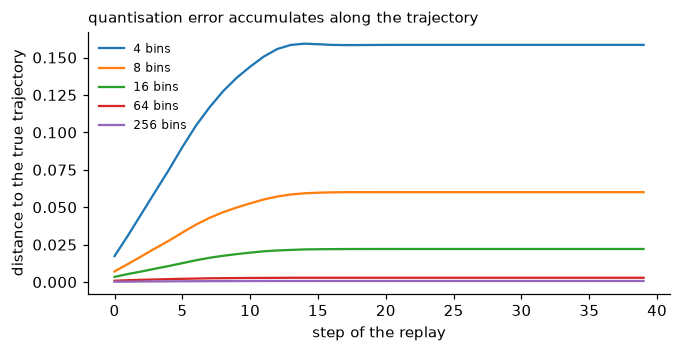

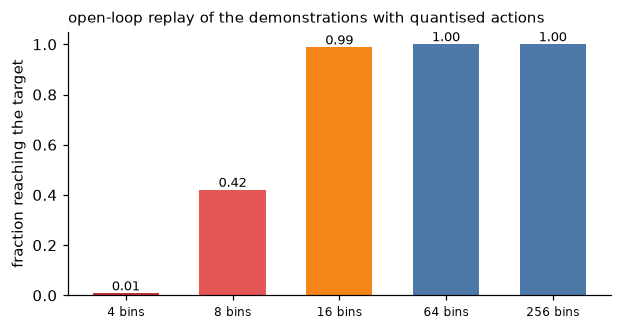

In [6]:
def replay(eps, binner, max_len=40):
    errs, hits = [], []
    for ep in eps:
        p, q = ep.robot[0].copy(), ep.robot[0].copy()
        track = []
        for t in range(min(ep.active_steps, max_len)):
            p = world.step(p, ep.actions[t], "ee")
            q = world.step(q, binner.roundtrip(ep.actions[t][None])[0].numpy(), "ee")
            track.append(np.linalg.norm(p - q))
        errs.append(track + [track[-1]] * (max_len - len(track)))
        hits.append(np.linalg.norm(q - ep.scene.objects[ep.targets[0]]) <= world.success_radius)
    return np.mean(errs, 0), float(np.mean(hits))

sub = reach_demos[:400]
curves, hit_rate = {}, {}
for n in (4, 8, 16, 64, 256):
    curves[f"{n} bins"], hit_rate[n] = replay(sub, ActionBinner(n, -1.5, 1.5))
plots.curves(np.arange(40), curves, "step of the replay", "distance to the true trajectory", "quantisation error accumulates along the trajectory", markers=False)
plots.bar_compare({f"{n} bins": v for n, v in hit_rate.items()}, "fraction reaching the target", "open-loop replay of the demonstrations with quantised actions", ylim=(0, 1.05), colors=["#c53030", "#e45756", "#f58518", "#4c78a8", "#4c78a8"])

Read the two plots together: the distance to the true trajectory **grows along the path** (every step adds a rounding error, and rounding the *same* action to the *same* bin is biased, so errors add up faster than a random walk) and then flattens once the robot parks at its target. With 4 bins
the robot ends about 3 action-steps off and almost never reaches the object (1 %); with 8 bins it still fails more than half the time (42 %); with 16 bins and above the replay is essentially exact. *Open-loop* the resolution matters a lot. A **closed-loop** policy re-observes at every step and can correct the drift, which is why coarse tokenisation can still work in practice (Step 6 tests exactly that).

## Step 4: Training an RT-2-style policy

We fine-tune the whole VLM so that, after `[image | "go to red" ]`, it emits the two action tokens. One action per call (`H = 1`, as in RT-2). The loss is the plain next-token cross-entropy; the model outputs a
*categorical distribution over the 256 bins* for each dimension.

step   750  loss 3.3697  (flow 3.370, token_acc 0.219)


step  1500  loss 3.0057  (flow 3.006, token_acc 0.164)


step  2250  loss 2.8525  (flow 2.853, token_acc 0.164)


step  3000  loss 2.6624  (flow 2.662, token_acc 0.141)
trained in 296 s; 318,144 parameters (the whole VLM is trained)


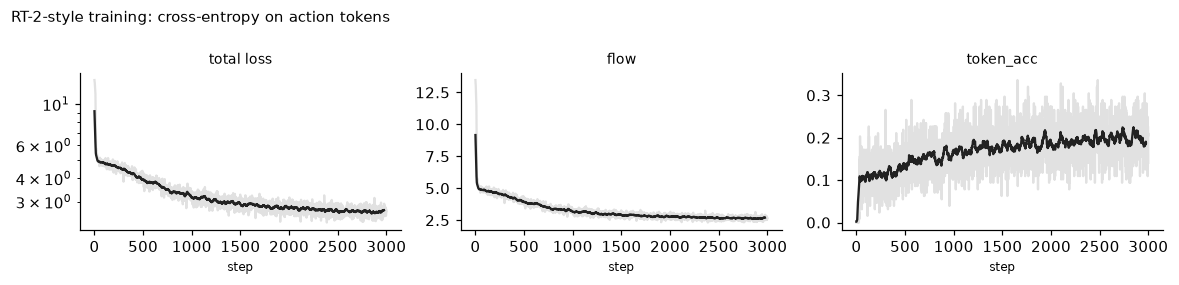

closed loop (one action per model call): {'success': 0.979, 'steps': 11.1, 'path': 0.496, 'wrong_first': 0.01}


In [7]:
reach1 = EmbodiedMixture([EmbodiedSource(world, reach_demos, EMBODIMENTS["point2d"], chunk_size=1)])
torch.manual_seed(0)
ar = AutoregressiveActionPolicy(vlm, ARConfig(chunk_size=1))
hist = PiTrainer(ar, reach1, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000, log_every=750)
ar.eval()
print(f"trained in {hist.seconds:.0f} s; {ar.parameter_counts()['total']:,} parameters (the whole VLM is trained)")
plots.plot_loss(hist, keys=("flow", "token_acc"), title="RT-2-style training: cross-entropy on action tokens")
ev1 = EmbodiedEvaluator(world, 1, 1, 50)
res = ev1.run(lambda b: ar.sample_actions(b), reach_scen)
print("closed loop (one action per model call):", res.summary())

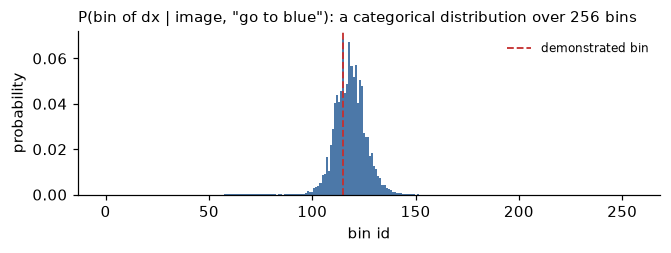

most likely bin: 115 | demonstrated bin: 115 | probability mass within ±3 bins of the demonstrated one: 0.36


In [8]:
# what the model "says": the distribution over bins for the first action dimension of one example
b1 = reach1.sample(1, np.random.default_rng(5))
with torch.no_grad():
    inp = ar.vlm.build_inputs(b1.images, b1.task)
    logits = ar.vlm.logits(ar.vlm.forward_layers(inp)[-1][:, -1])[0, ar.base : ar.base + 256]
probs = torch.softmax(logits, -1).numpy()
true_bin = int(ar.binner.encode(b1.actions[0, 0, :2])[0])
plots.plot_token_distribution(probs, true_bin, f'P(bin of dx | image, "{b1.task[0]}"): a categorical distribution over 256 bins')
print("most likely bin:", int(probs.argmax()), "| demonstrated bin:", true_bin, "| probability mass within ±3 bins of the demonstrated one:", round(float(probs[max(0, true_bin - 3): true_bin + 4].sum()), 2))

Note what the cross-entropy does to a *continuous* quantity: it treats bins 120 and 121 as completely unrelated classes. The model has to learn that neighbouring bins are neighbours from data (the probability above spreads
over adjacent bins, not onto a single spike). With a pre-trained LLM the numbers' ordering partly comes for free; in our from-scratch toy it is learned.

## Step 5: Why it is slow: sequential decoding

To emit an action the VLM decodes its tokens **one at a time**, each conditioned on the previous ones, so an action with `D` dimensions needs `D` forward passes, and a chunk of `H` actions needs `H·D`. A KV cache avoids
recomputing the prefix for every token (the cost of one extra token is small) but the passes stay **sequential**: nothing can run in parallel. Flow matching / diffusion, by contrast, produce the *whole* chunk in each of
their `K` evaluations.

We time a naive decoder (re-run everything for each token), a cached decoder (exact: same outputs), and a 10-step flow-matching head producing the same number of actions.

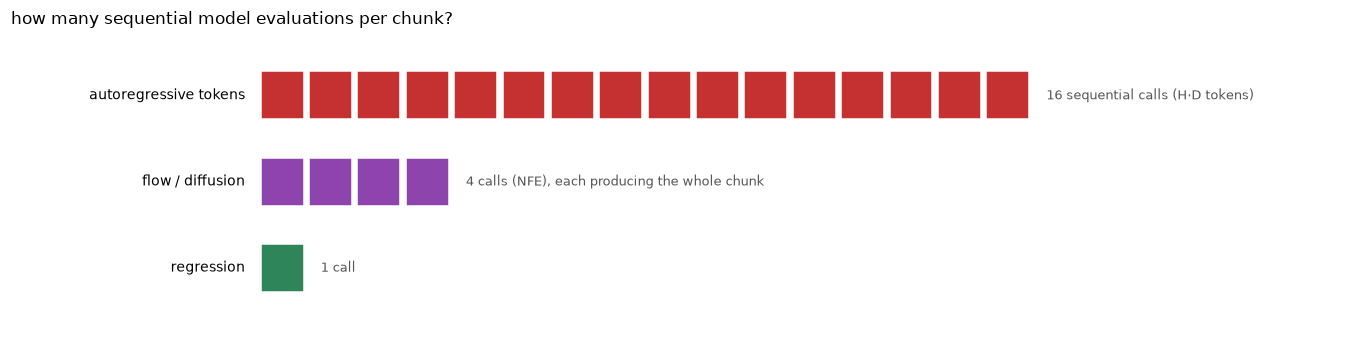

cached == naive (same tokens): True


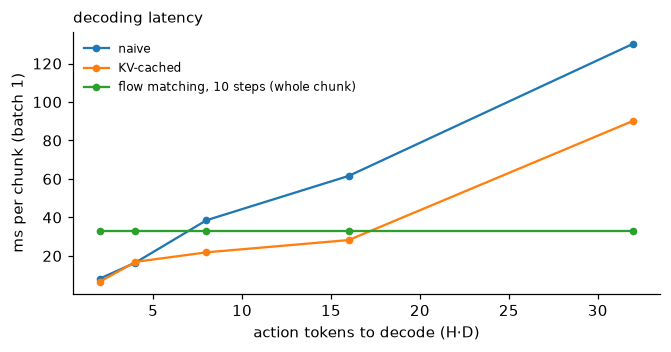

In [9]:
dg.fig_decode_timelines(tokens=16, nfe=4)
def ms(fn, reps=12):
    fn(); t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return 1000 * (time.perf_counter() - t0) / reps

one = reach.sample(1, np.random.default_rng(2))
rows = {"naive": [], "KV-cached": []}
Hs = [1, 2, 4, 8, 16]
for H in Hs:
    m = AutoregressiveActionPolicy(vlm, ARConfig(chunk_size=H)).eval()
    rows["naive"].append(ms(lambda: m.generate_naive(one))); rows["KV-cached"].append(ms(lambda: m.generate_cached(one)))
flow_ms = ms(lambda: SmolVLAPolicy(vlm, SmolVLAConfig(flow_convention="forward")).sample_actions(one, num_steps=10))
print("cached == naive (same tokens):", bool(torch.allclose(m.generate_cached(one), m.generate_naive(one))))
plots.curves([2 * h for h in Hs], {**rows, "flow matching, 10 steps (whole chunk)": [flow_ms] * len(Hs)}, "action tokens to decode (H·D)", "ms per chunk (batch 1)", "decoding latency", markers=True)

The consequence for control rate. If a call takes `t` seconds and yields `k` executable actions, the sustainable action rate is `k / t`: for RT-2 `k = 1` and 8 tokens per step; **RT-2-PaLI-X-55B reached 1-3 Hz and the 5B model about 5 Hz** (cloud TPUs),
OpenVLA 7B about 6 Hz on one RTX 4090, in both cases with one action per call. In our toy, the cached token decoder is faster than a 10-step flow head only below about 15 tokens (the crossing point in the plot above). A chunked head with a handful of denoising steps amortises one call over `H` actions: that is the practical reason π0 and successors moved to
continuous chunk heads (Step 18 measures it on our toy).

## Step 6: Bins vs success

Does more resolution always help? We train the same RT-2-style policy with 8, 32 and 256 bins (same VLM, same steps).

  8 bins: success 0.99, steps 10.8, final token accuracy 0.88


 32 bins: success 0.98, steps 11.0, final token accuracy 0.62


256 bins: success 0.98, steps 11.1, final token accuracy 0.19


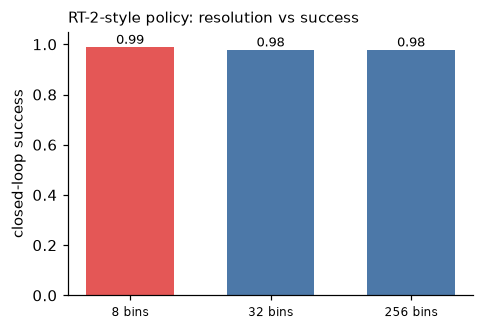

In [10]:
bin_results = {}
for nb in (8, 32, 256):
    if nb == 256:
        m, h = ar, hist
    else:
        torch.manual_seed(0)
        m = AutoregressiveActionPolicy(vlm, ARConfig(chunk_size=1, num_bins=nb)); h = PiTrainer(m, reach1, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000); m.eval()
    r = ev1.run(lambda b: m.sample_actions(b), reach_scen)
    bin_results[f"{nb} bins"] = r.success_rate
    print(f"{nb:3d} bins: success {r.success_rate:.2f}, steps {r.summary()['steps']}, final token accuracy {np.mean(h.series('token_acc')[-50:]):.2f}", flush=True)
plots.bar_compare(bin_results, "closed-loop success", "RT-2-style policy: resolution vs success", ylim=(0, 1.05), colors=["#e45756", "#4c78a8", "#4c78a8"])

**The result is the opposite of the open-loop one**: in closed loop, 8, 32 and 256 bins all succeed (≈ 0.98); the policy re-observes after every action and corrects any rounding. What does change is the *token accuracy* printed above: 0.88 with 8 bins, 0.62 with 32, 0.19 with 256: with many
near-identical classes the model rarely hits *exactly* the demonstrated bin (it lands in a neighbouring one, which costs nothing here). So in this easy 2-D task the resolution is not the bottleneck; it matters when the task needs *precision* (insertion, tight tolerances) or when errors are not corrected by feedback,
which is where RT-2 and OpenVLA's 256 bins per dimension come from. The cost of resolution is not accuracy but **vocabulary use and the loss landscape**: classification over 256 classes with sparse supervision.

# Part 2: Flow matching vs DDPM diffusion

## Step 7: The mathematics

Both families learn to turn Gaussian noise into actions; they differ in *what the network predicts* and *how the path from noise to data is defined*.

**Conditional flow matching (CFM)** (Lipman et al.; π0, GR00T N1, SmolVLA). Take a noise sample `x₀ ~ N(0, I)` and a data sample `x₁` (an action chunk). Define the **straight-line path**
$$x_t = (1-t)\,x_0 + t\,x_1,\qquad t\in[0,1],\qquad \frac{dx_t}{dt} = u = x_1 - x_0 .$$
The network `v_θ(x, t | o)` is trained to predict the conditional velocity: $\mathcal L = \mathbb E\,\|v_\theta(x_t, t\mid o) - (x_1 - x_0)\|^2$. At inference, integrate the **ODE** `dx/dt = v_θ(x, t)` from `t = 0` (noise) to `t = 1`
with `K` Euler steps: $x \leftarrow x + \tfrac1K v_\theta(x, t)$. (π0 writes the same thing with `t` reversed, noise at 1.)

**DDPM** (Ho et al.; Diffusion Policy). A fixed *forward* chain adds noise over `T` steps: $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$, and the network `ε_θ(x_t, t | o)` predicts the noise,
$\mathcal L = \mathbb E\,\|\varepsilon_\theta - \varepsilon\|^2$. Sampling reverses the chain **stochastically**: $x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\varepsilon_\theta\big) + \sigma_t z$ with fresh noise `z` at every
step: all `T` steps (`T = 100` in Diffusion Policy). **DDIM** reuses the *same* trained network along a deterministic path on a strided subset of steps.

| | flow matching | DDPM diffusion |
|---|---|---|
| training pairs | noise ↔ data joined by a **straight line** | noise levels `ᾱ_t` of a **fixed forward chain** |
| network predicts | velocity `x₁ − x₀` | noise `ε` |
| sampling | deterministic **ODE** (Euler, `K` steps) | **stochastic** reverse chain (`T` steps), or deterministic DDIM (`S ≪ T` steps) |
| time | continuous `t ∈ [0, 1]` | discrete `t ∈ {1…T}` |

One subtlety the slogan hides: the *conditional* path (one noise sample to one data sample) is straight, but the network is trained on **all** pairs through a point `x` and so learns their *average* direction: the
**marginal** field. Where the data has several modes the marginal field bends toward whichever mode is nearer, and sampled trajectories are not straight. Straightness is a property of the *training pairs*.

## Step 8: Both, in 2-D, on a bimodal distribution

Take the cleanest multimodal data there is: two Gaussian blobs at `(±2, 0)`. Same tiny MLP, same number of training steps, ten seconds of CPU for each method.

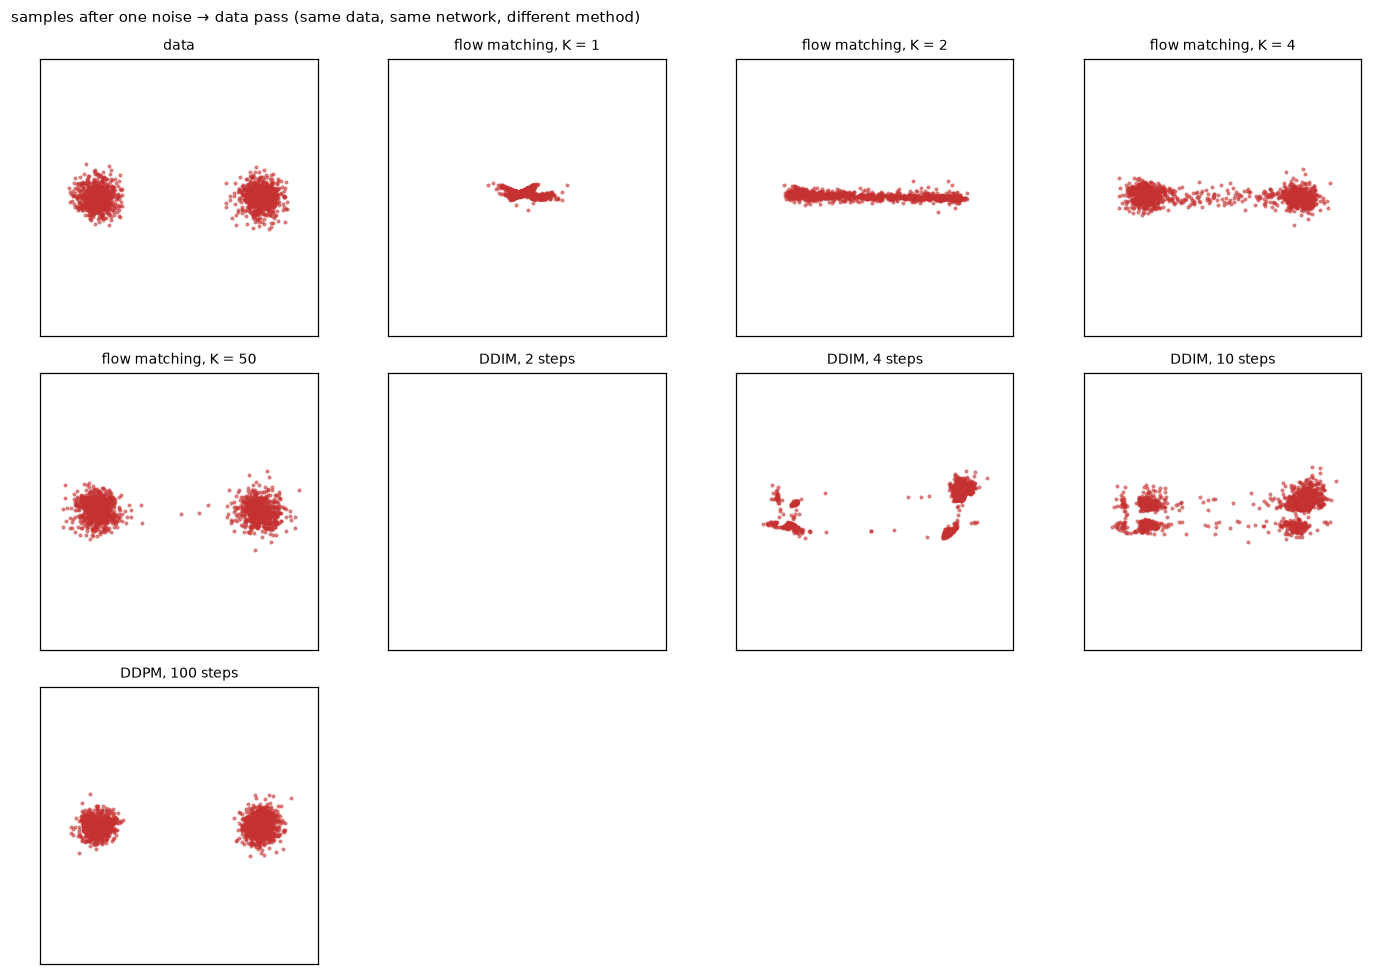

In [11]:
rng2 = np.random.default_rng(0)
data_fn = lambda n: toy2d.bimodal_data(n, rng2)
sched = DDPMSchedule(100, "cosine")
fm_net = toy2d.train_flow_2d(data_fn)
dd_net = toy2d.train_ddpm_2d(data_fn, sched)
N = 1500
fm_traj = {K: toy2d.sample_flow_2d(fm_net, N, K) for K in (1, 2, 4, 50)}
ddim_traj = {K: toy2d.sample_ddim_2d(dd_net, sched, N, K) for K in (2, 4, 10)}
ddpm_traj = toy2d.sample_ddpm_2d(dd_net, sched, N)
panels = {"data": data_fn(N)}
panels.update({f"flow matching, K = {K}": t[-1] for K, t in fm_traj.items()})
panels.update({f"DDIM, {K} steps": t[-1] for K, t in ddim_traj.items()})
panels["DDPM, 100 steps"] = ddpm_traj[-1]
plots.plot_2d_samples(panels, ncols=4, title="samples after one noise → data pass (same data, same network, different method)")

**Reading the panels.** *Flow matching with one Euler step* puts every sample **between** the modes (the average of the two blobs: with a single step the model can only follow the *mean* velocity), by `K = 4` the two modes are
resolved, and more steps sharpen them. DDIM needs a few steps too: one or two steps produce garbage, four or more resolve both modes. The stochastic 100-step DDPM chain is the reference. The lesson for actions: a **one-step
generative head collapses to the mean**, exactly like a regression head, so "few steps" has a floor.

Now the paths themselves: where do samples travel?

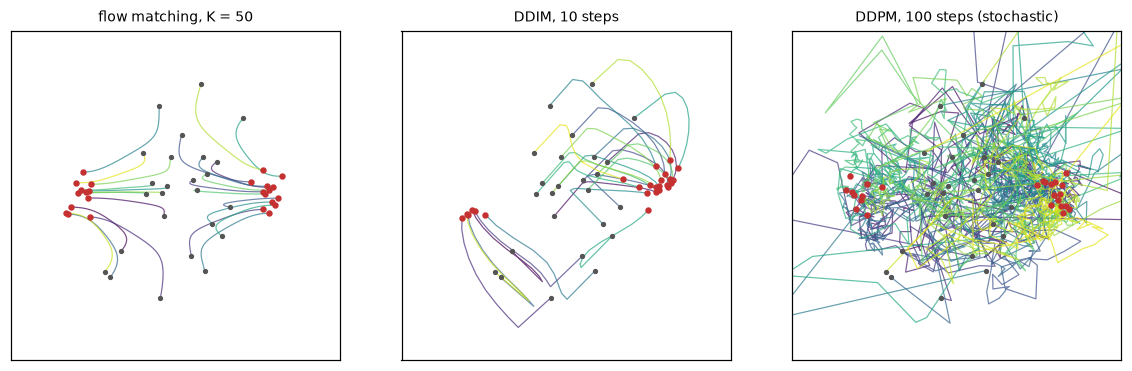

path straightness = (path length)/(distance start→end); 1 = perfectly straight
  flow matching K=50     1.21
  flow matching K=4      1.36
  DDIM 10                2.14
  DDPM 100              17.27


In [12]:
plots.plot_paths({"flow matching, K = 50": fm_traj[50], "DDIM, 10 steps": ddim_traj[10], "DDPM, 100 steps (stochastic)": ddpm_traj}, n_paths=25)
print("path straightness = (path length)/(distance start→end); 1 = perfectly straight")
for name, tr in (("flow matching K=50", fm_traj[50]), ("flow matching K=4", fm_traj[4]), ("DDIM 10", ddim_traj[10]), ("DDPM 100", ddpm_traj)):
    print(f"  {name:20s} {toy2d.path_straightness(tr):6.2f}")

The DDPM chain wanders (its reverse process injects fresh noise at every step: path length many times the straight distance), DDIM and flow matching follow smooth deterministic curves. Note flow matching's paths are **not**
straight either: they bend as they approach the modes, as the marginal field predicts.

## Step 9: Verification: the learned field against the exact optimum

For this data the optimal velocity field can be written in closed form, so we can check that the network learned *the right thing*. With `x₀ ~ N(0, I)` and `x₁ ~ ½N((−2,0), σ²I) + ½N((2,0), σ²I)`, `σ = 0.25`:
the point `x_t` is Gaussian with variance `s² = (1−t)² + t²σ²` around `tμ_m` for component `m`; conditioning on `x_t` gives the posterior mean of `x₁ − x₀`

$$u^\star(x,t) = \sum_m r_m(x)\Big[\mu_m + \frac{t\sigma^2-(1-t)}{s^2}\,(x - t\mu_m)\Big],\qquad r_m(x)\propto \mathcal N(x;\,t\mu_m,\, s^2 I).$$

We compare it with the trained network on points drawn from the training path distribution (and, as a warning, on a uniform grid).

relative error |learned − optimal| / |optimal|, on points drawn from the training path distribution: {'t = 0.1': 0.166, 't = 0.3': 0.104, 't = 0.5': 0.089, 't = 0.7': 0.077, 't = 0.9': 0.067}
…but on a uniform grid at t = 0.9 the relative error is 0.75: off the data the network was never trained


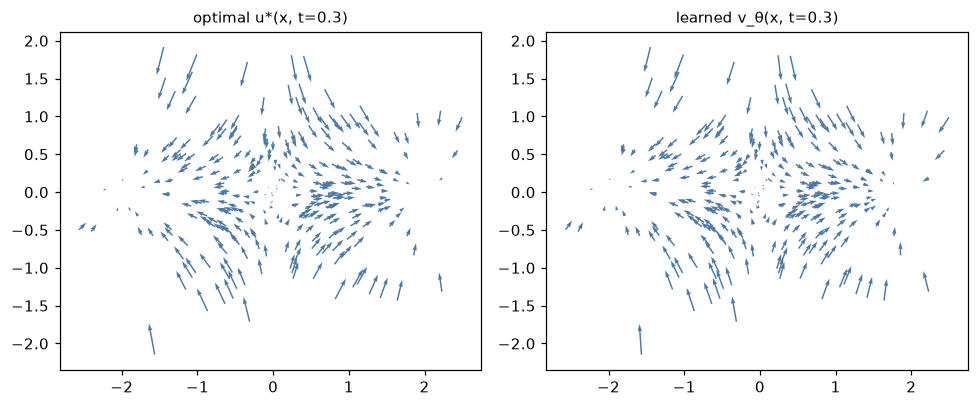

In [13]:
def optimal_velocity(x, t, mu=2.0, sigma=0.25):
    s2 = (1 - t) ** 2 + (t * sigma) ** 2
    mus = torch.tensor([[-mu, 0.0], [mu, 0.0]])
    logr = torch.stack([-((x - t * m) ** 2).sum(-1) / (2 * s2) for m in mus], -1)
    r = torch.softmax(logr, -1)
    u = 0
    for k, m in enumerate(mus):
        u = u + r[..., k:k + 1] * (m + (t * sigma ** 2 - (1 - t)) / s2 * (x - t * m))
    return u

rng_v = np.random.default_rng(5)
rel = {}
for t in (0.1, 0.3, 0.5, 0.7, 0.9):
    x1 = toy2d.bimodal_data(4000, rng_v); x0 = torch.randn_like(x1); xt = (1 - t) * x0 + t * x1       # points the network actually sees in training
    tt = torch.full((4000,), t)
    with torch.no_grad():
        learned = fm_net(xt, tt); exact = optimal_velocity(xt, t)
    rel[f"t = {t}"] = float((learned - exact).norm(dim=1).mean() / exact.norm(dim=1).mean())
print("relative error |learned − optimal| / |optimal|, on points drawn from the training path distribution:", {k: round(v, 3) for k, v in rel.items()})
# the same comparison on a *uniform grid* (includes regions the data never visits)
g = torch.linspace(-3, 3, 13)
xx = torch.stack(torch.meshgrid(g, g, indexing="ij"), -1).reshape(-1, 2)
with torch.no_grad():
    grid_err = float((fm_net(xx, torch.full((len(xx),), 0.9)) - optimal_velocity(xx, 0.9)).norm(dim=1).mean() / optimal_velocity(xx, 0.9).norm(dim=1).mean())
print(f"…but on a uniform grid at t = 0.9 the relative error is {grid_err:.2f}: off the data the network was never trained")
pts = toy2d.bimodal_data(1, rng_v)  # (unused, keeps the generator advancing)
x1 = toy2d.bimodal_data(300, rng_v); x0 = torch.randn_like(x1); t0 = 0.3; xt = (1 - t0) * x0 + t0 * x1
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
with torch.no_grad():
    fields = (("optimal u*(x, t=0.3)", optimal_velocity(xt, t0)), ("learned v_θ(x, t=0.3)", fm_net(xt, torch.full((300,), t0))))
for ax, (name, field) in zip(axes, fields):
    ax.quiver(xt[:, 0], xt[:, 1], field[:, 0], field[:, 1], color="#4c78a8", scale=40)
    ax.set_aspect("equal"); ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

On the points the network is trained on, it reproduces the analytic field to within **7-17 %** of its magnitude (the residual is a small-MLP, 3000-step effect). On a uniform grid that includes regions the data never visits the error is huge: a lesson in its own right (generative heads are only trustworthy *on the data manifold*; this is also why out-of-distribution observations are dangerous).
The arrows at `t = 0.3` show the bend toward the nearer mode: the field points *toward the average of the data* near the origin and splits into two basins, which is exactly why a single Euler step lands in the middle.

## Step 10: How many network calls (NFE)? Averaged over seeds

"Fewer NFEs" is the practical question. We train each method on **five seeds** and score the fraction of samples that land *inside a mode* as a function of the number of network evaluations.

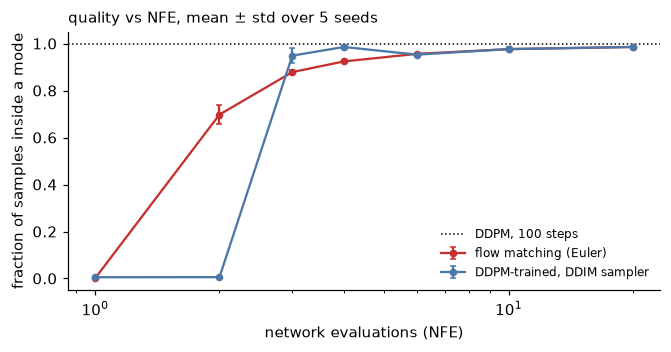

NFE = 1: {'flow': 0.0, 'ddim': 0.01} | NFE = 4: {'flow': 0.92, 'ddim': 0.99}


In [14]:
def in_modes(x):
    return float(((x[:, 0].abs() - 2).abs() < 0.8).float().mean())
nfes_fm, nfes_dd = (1, 2, 3, 4, 6, 10, 20), (1, 2, 3, 4, 6, 10, 20)
res_fm = {k: [] for k in nfes_fm}; res_dd = {k: [] for k in nfes_dd}
for seed in range(5):
    r = np.random.default_rng(seed); fn = lambda n, r=r: toy2d.bimodal_data(n, r)
    f = toy2d.train_flow_2d(fn, seed=seed); d = toy2d.train_ddpm_2d(fn, sched, seed=seed)
    for k in nfes_fm: res_fm[k].append(in_modes(toy2d.sample_flow_2d(f, 1500, k, seed=seed)[-1]))
    for k in nfes_dd: res_dd[k].append(in_modes(toy2d.sample_ddim_2d(d, sched, 1500, k, seed=seed)[-1]))
fig, ax = plt.subplots(figsize=(6.2, 3.3))
for name, res, col in (("flow matching (Euler)", res_fm, "#c53030"), ("DDPM-trained, DDIM sampler", res_dd, "#4c78a8")):
    m_ = np.array([np.mean(v) for v in res.values()]); s_ = np.array([np.std(v) for v in res.values()])
    ax.errorbar(list(res), m_, yerr=s_, marker="o", ms=4, label=name, color=col, capsize=2)
ax.axhline(in_modes(ddpm_traj[-1]), color="k", ls=":", lw=1, label="DDPM, 100 steps")
ax.set_xscale("log"); ax.set_xlabel("network evaluations (NFE)"); ax.set_ylabel("fraction of samples inside a mode"); ax.set_ylim(-0.05, 1.05)
ax.legend(fontsize=8, frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.set_title("quality vs NFE, mean ± std over 5 seeds", fontsize=10, loc="left")
plt.tight_layout(); plt.show()
print("NFE = 1:", {"flow": round(float(np.mean(res_fm[1])), 2), "ddim": round(float(np.mean(res_dd[1])), 2)}, "| NFE = 4:", {"flow": round(float(np.mean(res_fm[4])), 2), "ddim": round(float(np.mean(res_dd[4])), 2)})

**Reading the curve** (the honest, nuanced result). At **one** evaluation both methods collapse (≈ 0 % of samples inside a mode). At **two**, flow matching already puts about 70 % of its samples in a mode while DDIM is still at ≈ 0 %: the Euler sampler of a straight-ish field degrades much more gracefully. From **three** evaluations on, *both* resolve
the modes (≥ 90 %) and DDIM is as good as flow matching, sometimes better. Flow matching's *training* is also simpler (one regression target, continuous time, no schedule to tune, no `1/√ᾱ` blow-up at the first step), but "flow matching needs far fewer steps than diffusion" is **not** a law of nature here: DDIM already closes most of that gap. The robot-learning papers pick flow matching (π0: 10 Euler steps) for
simplicity, continuous outputs and well-behaved training, with step counts of the same order as DDIM's 10; the real gain is at the *extreme low-step end* (2-3 evaluations).

# Part 3: Diffusion Policy

## Step 11: DDPM on action chunks

**Diffusion Policy** (Chi et al., 2023) applies exactly the DDPM recipe above to *action sequences* conditioned on observations, plus a few robotics-specific choices: it predicts a **chunk** of `T_p` actions, executes only the first
`T_a` of them before re-planning (**receding-horizon control**, Part 4), conditions on images through a visual encoder, and uses a (1-D CNN or) **transformer** denoiser. For real-time control it trains with `T = 100` steps and samples with
**DDIM, 10 steps** (≈ 0.1 s on an RTX 3080).

`DiffusionPolicy` here reuses the SmolVLA expert with an ε-prediction target on a cosine schedule: the same VLM features, so a comparison with flow matching changes only the objective and the sampler.

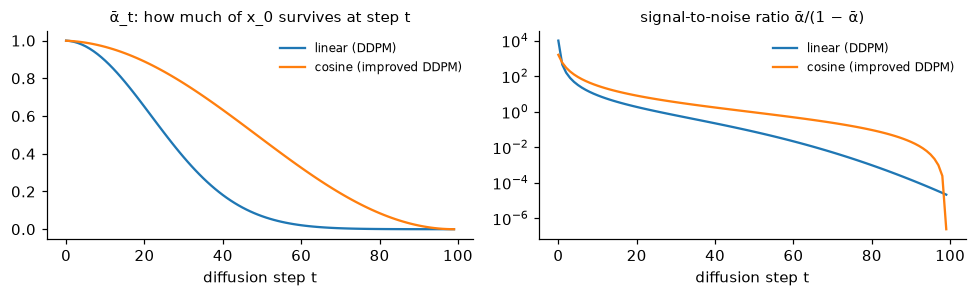

a real demonstrated action chunk (drawn as the path it would follow), progressively noised by the forward process:


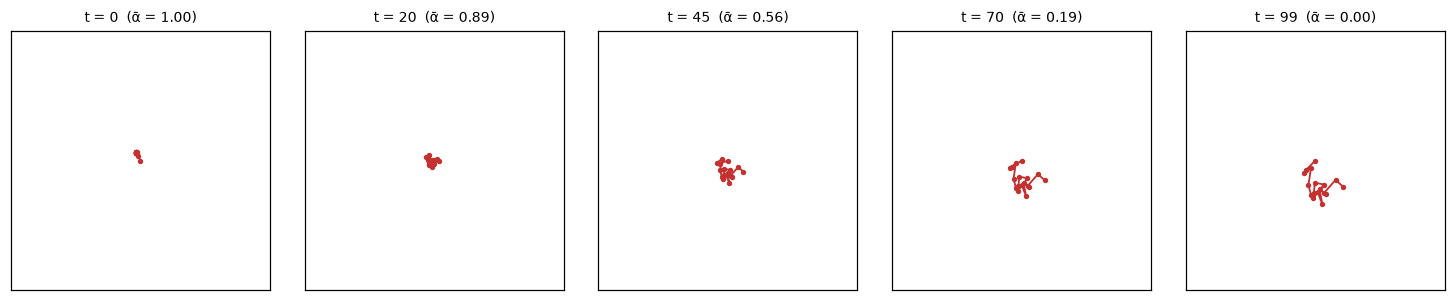

In [15]:
lin, cos_ = DDPMSchedule(100, "linear"), DDPMSchedule(100, "cosine")
plots.plot_noise_schedules({"linear (DDPM)": lin, "cosine (improved DDPM)": cos_}, 100)
chunk = batch.actions[0, :, :2].numpy()
print("a real demonstrated action chunk (drawn as the path it would follow), progressively noised by the forward process:")
plots.plot_chunk_noising(chunk, cos_, steps=(0, 20, 45, 70, 99))

The forward process destroys the chunk gradually (the cosine schedule more evenly than the linear one, whose signal-to-noise ratio collapses early). Training picks a random step `t`, noises a demonstrated chunk to that
level and asks the network for the noise. Sampling starts from pure noise at `t = T` and denoises.

## Step 12: Training and comparing all four heads on the multimodal task

Now the policy-level comparison on `"go to any"` (two valid objects). Five action heads on the **same VLM**, trained for the same 3000 steps: two **regression** heads (L1 and MSE on the chunk: predict one answer), **flow matching**,
**DDPM / DDIM diffusion**, and **autoregressive tokens** (RT-2-style, a 16-action chunk = 32 tokens). Besides closed-loop success we measure **mode coverage**: for each of 24 scenes we draw 24 chunks for the *same* observation and
ask which object each one is aimed at (within 20°). A policy that models the distribution splits its samples between the objects; one that averages aims at neither.

In [16]:
heads = {}
def train(name, model, data, steps=3000):
    h = PiTrainer(model, data, batch_size=64, lr=2e-3, grad_clip=10.0).fit(steps)
    heads[name] = (model, h.seconds)
    print(f"{name:26s} trained in {h.seconds:4.0f} s", flush=True)
    return model
torch.manual_seed(0); train("regression (L1)", SmolVLAPolicy(vlm, SmolVLAConfig(objective="regression")), any_)
torch.manual_seed(0); train("regression (MSE)", SmolVLAPolicy(vlm, SmolVLAConfig(objective="mse")), any_)
torch.manual_seed(0); train("flow matching", SmolVLAPolicy(vlm, SmolVLAConfig(flow_convention="forward")), any_)
torch.manual_seed(0); train("DDPM diffusion", DiffusionPolicy(vlm, SmolVLAConfig(), DDPMSchedule(100, "cosine")), any_)
any16 = EmbodiedMixture([EmbodiedSource(world, any_demos, EMBODIMENTS["point2d"], chunk_size=16)])
torch.manual_seed(0); train("autoregressive tokens", AutoregressiveActionPolicy(vlm, ARConfig(chunk_size=16)), any16)
heads["autoregressive tokens"][0].eval()

regression (L1)            trained in  296 s


regression (MSE)           trained in  271 s


flow matching              trained in  339 s


DDPM diffusion             trained in  335 s


autoregressive tokens      trained in  454 s


AutoregressiveActionPolicy(
  (vlm): ToyVLM(
    (vision): PatchShuffleVisionEncoder(
      (patchify): Conv2d(5, 64, kernel_size=(4, 4), stride=(4, 4))
      (merge): Linear(in_features=256, out_features=64, bias=True)
    )
    (tok_emb): Embedding(310, 64)
    (pos_emb): Embedding(96, 64)
    (layers): ModuleList(
      (0-5): 6 x ExpertLayer(
        (attn_norm): RMSNorm()
        (mlp_norm): RMSNorm()
        (q): Linear(in_features=64, out_features=64, bias=False)
        (k): Linear(in_features=64, out_features=64, bias=False)
        (v): Linear(in_features=64, out_features=64, bias=False)
        (o): Linear(in_features=64, out_features=64, bias=False)
        (mlp): SwiGLU(
          (gate): Linear(in_features=64, out_features=128, bias=False)
          (up): Linear(in_features=64, out_features=128, bias=False)
          (down): Linear(in_features=128, out_features=64, bias=False)
        )
      )
    )
    (final_norm): RMSNorm()
    (lm_head): Linear(in_features=64, out_fe

In [17]:
policy_fns = {
    "regression (L1)": (lambda b: heads["regression (L1)"][0].sample_actions(b), 1),
    "regression (MSE)": (lambda b: heads["regression (MSE)"][0].sample_actions(b), 1),
    "flow matching, K=10": (lambda b: heads["flow matching"][0].sample_actions(b, num_steps=10), 10),
    "diffusion, DDIM 10": (lambda b: heads["DDPM diffusion"][0].sample_actions(b, method="ddim", num_steps=10), 10),
    "diffusion, DDPM 100": (lambda b: heads["DDPM diffusion"][0].sample_actions(b, method="ddpm"), 100),
    "tokens (sampled)": (lambda b: heads["autoregressive tokens"][0].sample_actions(b, temperature=1.0), 32),
    "tokens (greedy)": (lambda b: heads["autoregressive tokens"][0].sample_actions(b, temperature=0.0), 32),
}
table = {}
ev_open = EmbodiedEvaluator(world, 16, 16, 50)         # executes the *whole* 16-step chunk before looking again
for name, (fn, nfe) in policy_fns.items():
    one = any16.sample(1, np.random.default_rng(3))
    t_ms = ms(lambda: fn(one), reps=5)
    s = ev.run(fn, any_scen).success_rate
    s_open = ev_open.run(fn, any_scen).success_rate
    mc = mode_coverage(fn, world, n_scenes=24, samples=24)
    table[name] = dict(success=s, success_open=s_open, aimed=mc.aimed, balance=mc.balance, neither=mc.neither, nfe=nfe, ms=t_ms)
    print(f"{name:22s} success {s:.2f} (re-plan every 16 steps {s_open:.2f}) | chunks aimed at an object {mc.aimed:.2f} (object A {mc.first:.2f}, B {mc.second:.2f}, neither {mc.neither:.2f}) | balance {mc.balance:.2f} | sequential calls {nfe:3d} | {t_ms:6.1f} ms/chunk", flush=True)

regression (L1)        success 0.49 (re-plan every 16 steps 0.41) | chunks aimed at an object 0.62 (object A 0.38, B 0.25, neither 0.38) | balance 0.80 | sequential calls   1 |    3.0 ms/chunk


regression (MSE)       success 0.74 (re-plan every 16 steps 0.55) | chunks aimed at an object 0.17 (object A 0.04, B 0.12, neither 0.83) | balance 0.50 | sequential calls   1 |    2.4 ms/chunk


flow matching, K=10    success 0.67 (re-plan every 16 steps 0.53) | chunks aimed at an object 0.67 (object A 0.35, B 0.32, neither 0.33) | balance 0.95 | sequential calls  10 |   11.1 ms/chunk


diffusion, DDIM 10     success 0.19 (re-plan every 16 steps 0.10) | chunks aimed at an object 0.51 (object A 0.23, B 0.28, neither 0.49) | balance 0.90 | sequential calls  10 |   11.9 ms/chunk


diffusion, DDPM 100    success 0.25 (re-plan every 16 steps 0.15) | chunks aimed at an object 0.40 (object A 0.18, B 0.23, neither 0.60) | balance 0.87 | sequential calls 100 |   89.2 ms/chunk


tokens (sampled)       success 0.18 (re-plan every 16 steps 0.19) | chunks aimed at an object 0.24 (object A 0.14, B 0.10, neither 0.76) | balance 0.83 | sequential calls  32 |   47.4 ms/chunk


tokens (greedy)        success 0.11 (re-plan every 16 steps 0.14) | chunks aimed at an object 0.29 (object A 0.17, B 0.12, neither 0.71) | balance 0.86 | sequential calls  32 |   44.2 ms/chunk


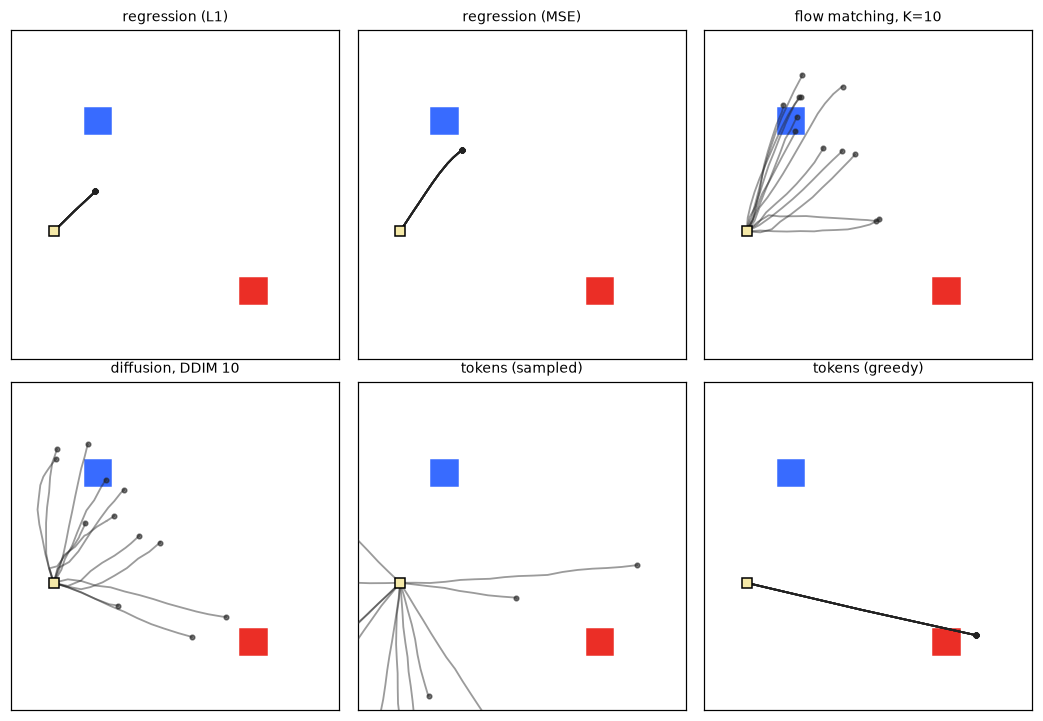

In [18]:
# what do the chunks look like for ONE scene? twelve samples of the first chunk per policy (a deterministic policy gives twelve identical paths)
scene = any_scen[5]
obs = EmbodiedEvaluator(world, 16, 8, 1).observe([scene] * 12, np.repeat(scene.scene.robot[None, None, :], 12, 0).astype(np.float32), np.full(12, -1.0), 0)
shown = ["regression (L1)", "regression (MSE)", "flow matching, K=10", "diffusion, DDIM 10", "tokens (sampled)", "tokens (greedy)"]
plots.plot_first_chunks(world, scene, {name: policy_fns[name][0](obs).cpu().numpy() for name in shown}, ncols=3)

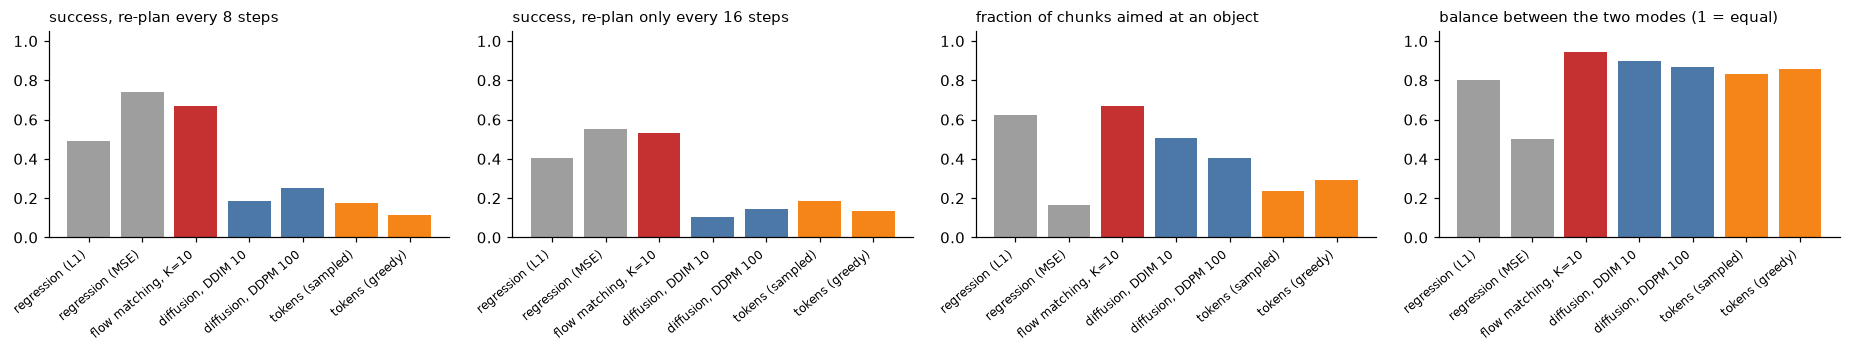

In [19]:
names = list(table)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.3), facecolor="white")
col = ["#9e9e9e", "#9e9e9e", "#c53030", "#4c78a8", "#4c78a8", "#f58518", "#f58518"]
panels = (("success", "success, re-plan every 8 steps"), ("success_open", "success, re-plan only every 16 steps"), ("aimed", "fraction of chunks aimed at an object"), ("balance", "balance between the two modes (1 = equal)"))
for ax, (key, label) in zip(axes, panels):
    ax.bar(range(len(names)), [table[n][key] for n in names], color=col)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=40, ha="right", fontsize=8); ax.set_ylim(0, 1.05); ax.set_title(label, fontsize=9.5, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**What to take from this** (one seed and 96 scenes, so differences of ~10 points are noise; read the *patterns*, not the exact ranks). Start with the figure of first chunks for one scene:

* **A regression head draws one path, and for MSE it is the average.** Trained on two equally valid answers, the MSE head learns their *mean*: its path heads **between** the two objects (the "neither" column: 83 % of its first chunks aim at neither). The L1 head learns a per-coordinate *median*, which for a symmetric mixture is ambiguous: it sometimes commits to one object and sometimes lands between them.
  The generative heads (flow, diffusion, sampled tokens) draw **different paths on each sample**, some to each object: they represent the *distribution*; their "balance" is near 1.
* **…but the closed-loop success of regression can hide this.** The MSE head still succeeds in 74 % of the episodes when it re-plans every 8 steps (55 % when it re-plans only every 16). The reason is instructive: after the first few steps toward the midpoint the robot is in a state that no demonstration ever visited (a demonstration always runs straight at *one* object), the policy extrapolates, and the symmetry is broken by the *state*.
  Closed-loop feedback can rescue an averaging policy on an easy task. It cannot when the compromise is **unsafe** (the mean of "go around the left of the obstacle" and "go around the right" is "through the obstacle") or when the commitment has to survive several seconds. Mode coverage, not success on a forgiving task, is the right test of a head's expressiveness.
* **Among the generative heads, flow matching has the best closed-loop success at this budget** (0.67 / 0.53). **Diffusion trails** (0.19-0.25): its samples are balanced but imprecise, so fewer chunks end on an object. Do not over-read that: ε-prediction over 100 noise levels is a harder regression problem than a single straight-line target, and the published Diffusion Policy trains much longer, with EMA weights.
  "Diffusion is worse" is a statement about *this budget*.
* **Autoregressive tokens can express multimodality** (a categorical distribution can put mass on two bins) *if you sample*; **greedy decoding** picks the single most likely token at every step and cannot mix the modes. Here the 32-token chunk is also simply hard to learn at this budget: most chunks do not end on an object.
* **Cost.** The last two columns of the printout: sequential network evaluations per chunk and wall time. Regression: 1; flow / DDIM: 10; DDPM: 100; tokens: 32.

## Step 13: What is different between DDIM, DDPM and the sampler `η`?

DDIM has a knob, `η`: `η = 0` is deterministic (the probability-flow ODE), `η = 1` adds as much noise as the DDPM chain. We sample the *same trained diffusion policy* with different samplers and step counts.

In [20]:
dpol = heads["DDPM diffusion"][0]
rows = {}
for name, kw in {"DDIM η=0, 4 steps": dict(method="ddim", num_steps=4, eta=0.0), "DDIM η=0, 10 steps": dict(method="ddim", num_steps=10, eta=0.0),
                 "DDIM η=0.5, 10 steps": dict(method="ddim", num_steps=10, eta=0.5), "DDIM η=1, 10 steps": dict(method="ddim", num_steps=10, eta=1.0),
                 "DDIM η=0, 50 steps": dict(method="ddim", num_steps=50, eta=0.0), "DDPM, 100 steps": dict(method="ddpm")}.items():
    fn = lambda b, kw=kw: dpol.sample_actions(b, **kw)
    mc = mode_coverage(fn, world, n_scenes=24, samples=24)
    rows[name] = dict(success=ev.run(fn, any_scen).success_rate, balance=mc.balance, aimed=mc.aimed)
    print(f"{name:24s} success {rows[name]['success']:.2f} | aimed {rows[name]['aimed']:.2f} | balance {rows[name]['balance']:.2f}", flush=True)

DDIM η=0, 4 steps        success 0.19 | aimed 0.52 | balance 0.95


DDIM η=0, 10 steps       success 0.18 | aimed 0.50 | balance 0.97


DDIM η=0.5, 10 steps     success 0.19 | aimed 0.49 | balance 0.94


DDIM η=1, 10 steps       success 0.17 | aimed 0.49 | balance 0.94


DDIM η=0, 50 steps       success 0.19 | aimed 0.44 | balance 0.94


DDPM, 100 steps          success 0.22 | aimed 0.40 | balance 0.90


one chunk being denoised: DDIM (10 steps) and DDPM (100 steps, stochastic):


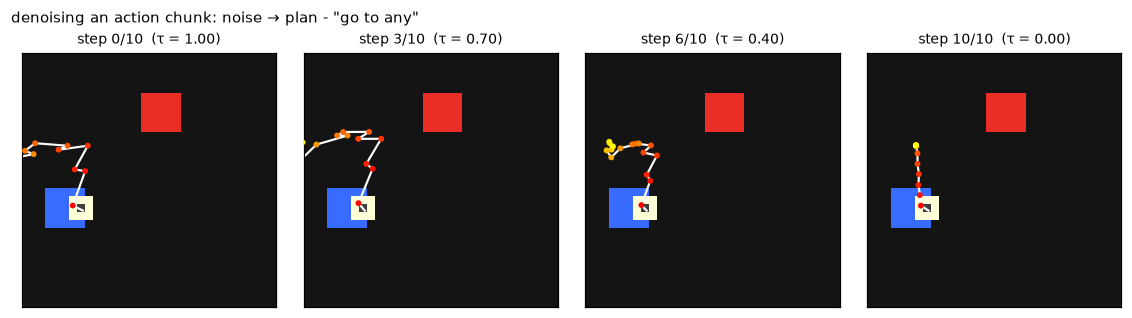

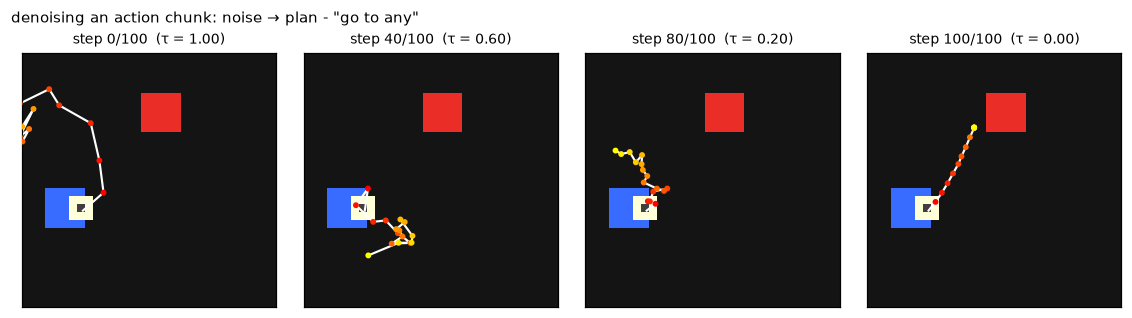

In [21]:
b8 = any16.sample(4, np.random.default_rng(8))
_, traj_ddim = dpol.sample_actions(b8, method="ddim", num_steps=10, return_trajectory=True)
_, traj_ddpm = dpol.sample_actions(b8, method="ddpm", return_trajectory=True)
print("one chunk being denoised: DDIM (10 steps) and DDPM (100 steps, stochastic):")
vplots.plot_denoising(b8, traj_ddim, example=0, steps_to_show=[0, 3, 6, 10]) if hasattr(vplots, "plot_denoising") else None
vplots.plot_denoising(b8, traj_ddpm, example=0, steps_to_show=[0, 40, 80, 100]) if hasattr(vplots, "plot_denoising") else None

The differences between these rows are within the noise of a 96-scene evaluation: more steps, `η > 0` or the full 100-step ancestral chain do **not** buy a clear improvement over 10 deterministic DDIM steps (the usual Diffusion Policy deployment), while the 100-step chain costs 10× the compute. The balance column stays near 1 for all of them: the *sampler* does not change which modes the *trained network* covers.

# Part 4: Chunked action prediction

## Step 14: Why chunks?

A single-step policy `π(a_t | o_t)` is queried at every control step; a **chunk** policy `π(a_t … a_{t+H-1} | o_t)` is queried once per `k ≤ H` steps. **ACT** gives two reasons: *"This reduces the effective horizon of the task by k-fold,
mitigating compounding errors"* (the policy's own mistakes get fewer chances to compound) and it handles *"temporally correlated confounders, such as pauses in demonstrations"* that a Markovian single-step policy cannot model.
For VLAs there is a third, practical reason: **one expensive model call is amortised over `H` actions**, which raises the control rate a slow VLM can sustain (π0 and SmolVLA predict 50 actions, π0.5 and GR00T N1 16).

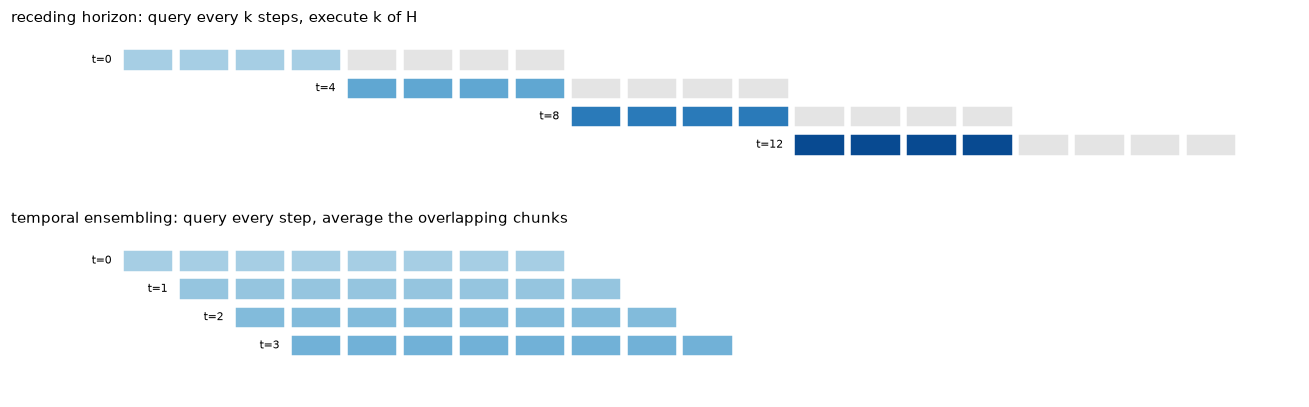

In [22]:
dg.fig_chunk_execution(H=8, k=4)

Two ways to *use* a chunk, both implemented in `ChunkedRunner`:

* **receding horizon** (Diffusion Policy, π0): execute the first `k` actions, re-plan;
* **temporal ensembling** (ACT): re-plan at *every* step and execute the weighted average of all earlier chunks' predictions for the current step, with weights `exp(−m·i)` (`i = 0` is the oldest prediction). It smooths the trajectory at the cost of one model call per step.

## Step 15: Chunk length vs success, with execution noise

We train three flow-matching policies with chunk lengths `H = 1, 4, 16` (same VLM, same data, 3000 steps each) and run each *open-loop for its whole chunk* (`k = H`) under increasing **execution noise** (the executed action
differs from the commanded one: the mechanism behind compounding error; σ is in units of one action step, so σ = 1 means the noise is as large as the action itself). `H = 1` re-plans at every step, so it is the closed-loop reference.

H =  1 trained in 184 s


H =  4 trained in 238 s


H = 16 trained in 270 s


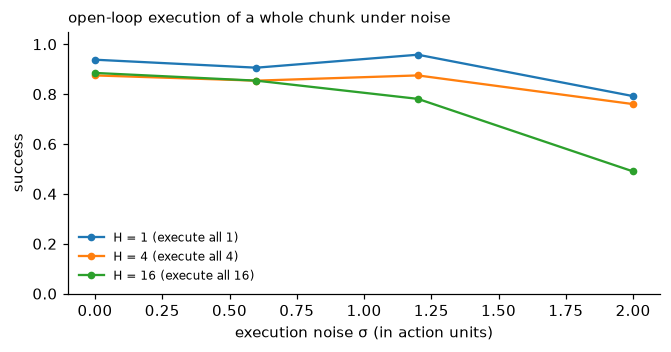

model calls per episode (no noise): {1: 15.5, 4: 5.4, 16: 2.0}


In [23]:
chunk_models, chunk_res = {}, {}
for H in (1, 4, 16):
    d = EmbodiedMixture([EmbodiedSource(world, reach_demos, EMBODIMENTS["point2d"], chunk_size=H)])
    torch.manual_seed(0)
    m = SmolVLAPolicy(vlm, SmolVLAConfig(chunk_size=H, flow_convention="forward"))
    h = PiTrainer(m, d, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000); chunk_models[H] = m
    print(f"H = {H:2d} trained in {h.seconds:.0f} s", flush=True)
noises = (0.0, 0.6, 1.2, 2.0)
for H in (1, 4, 16):
    for noise in noises:
        chunk_res[(H, noise)] = ChunkedRunner(world, H, H, action_noise=noise, max_steps=60).run(lambda b: chunk_models[H].sample_actions(b), reach_scen).summary()
plots.curves(list(noises), {f"H = {H} (execute all {H})": [chunk_res[(H, n)]["success"] for n in noises] for H in (1, 4, 16)},
             "execution noise σ (in action units)", "success", "open-loop execution of a whole chunk under noise", ylim=(0, 1.05))
print("model calls per episode (no noise):", {H: chunk_res[(H, 0.0)]["calls"] for H in (1, 4, 16)})

Longer chunks cut the number of model calls roughly in proportion (about 15 calls per episode at `H = 1`, 5 at `H = 4`, 2 at `H = 16`). With little noise all three are comparable (≈ 0.9): a chunk is executed faithfully. As the noise grows, executing the whole chunk open-loop lets errors accumulate with no chance of correction: `H = 16` falls to about 0.5 at σ = 2 while `H = 1` (a fresh observation every step) keeps ≈ 0.8.
This is the trade-off every chunked VLA navigates, and the reason chunks are rarely executed in full.

## Step 16: Execute only part of the chunk, and what *kind* of action you chunk

Take the `H = 16` policy and vary how many actions `k` we execute before re-planning, at two noise levels. And compare two *semantics* of a chunk:

* **relative** actions (what our policy outputs): "move by `Δ`". Executed open-loop, an error is never undone: the robot just carries it forward;
* **absolute** targets (what ACT predicts: joint-position targets): "go to the point `p`". We anchor the chunk's displacements at the position where it was predicted to get *waypoints* and command, at every step, the motion that closes the gap to
  the current waypoint, so noise is corrected on the next step *without any new model call*.

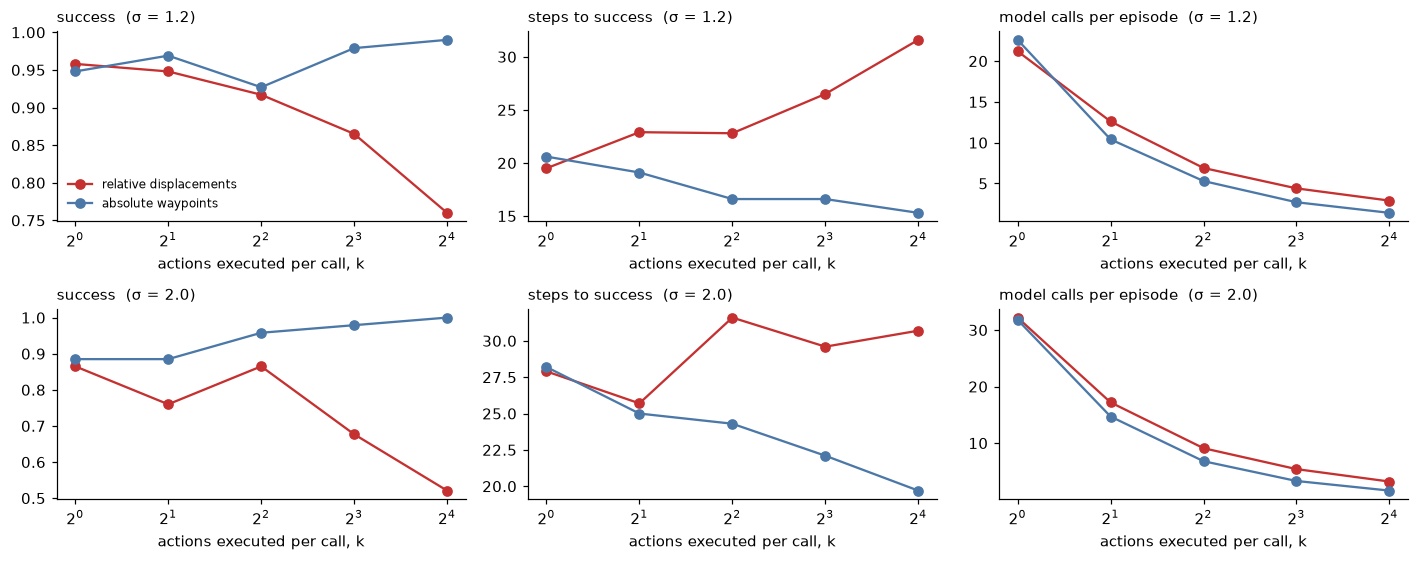

σ = 1.2: executing all 16 actions open-loop → relative 0.76, absolute 0.99; re-planning every step → relative 0.96, absolute 0.95
σ = 2.0: executing all 16 actions open-loop → relative 0.52, absolute 1.00; re-planning every step → relative 0.86, absolute 0.89


In [24]:
m16 = chunk_models[16]
exec_res = {}
for noise in (1.2, 2.0):
    for absolute in (False, True):
        for k in (1, 2, 4, 8, 16):
            exec_res[(noise, absolute, k)] = ChunkedRunner(world, 16, k, action_noise=noise, absolute=absolute, max_steps=60).run(lambda b: m16.sample_actions(b), reach_scen).summary()
ks = [1, 2, 4, 8, 16]
fig, axes = plt.subplots(2, 3, figsize=(13, 5.2), facecolor="white")
for r, noise in enumerate((1.2, 2.0)):
    for ax, key, lab in zip(axes[r], ("success", "steps", "calls"), ("success", "steps to success", "model calls per episode")):
        for absolute, name, col in ((False, "relative displacements", "#c53030"), (True, "absolute waypoints", "#4c78a8")):
            ax.plot(ks, [exec_res[(noise, absolute, k)][key] for k in ks], "o-", label=name, color=col)
        ax.set_xscale("log", base=2); ax.set_xlabel("actions executed per call, k"); ax.set_title(f"{lab}  (σ = {noise})", fontsize=9.5, loc="left"); ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
for noise in (1.2, 2.0):
    print(f"σ = {noise}: executing all 16 actions open-loop → relative {exec_res[(noise, False, 16)]['success']:.2f}, absolute {exec_res[(noise, True, 16)]['success']:.2f}; re-planning every step → relative {exec_res[(noise, False, 1)]['success']:.2f}, absolute {exec_res[(noise, True, 1)]['success']:.2f}")

Two effects. (1) For **relative** actions, re-planning more often (small `k`) is what lets the policy correct noise: success rises as `k` shrinks, at the price of more model calls: the "action horizon" trade-off of Diffusion Policy (too long is unresponsive) and SmolVLA's
Table 13 (updating observations more often raises success). (2) With **absolute** targets, even the *whole* chunk executed open-loop is robust (a low-level tracking loop corrects the noise every step), so you can keep the model calls at
`1/H` per step without paying for it. Absolute position targets plus a tracking controller are why ACT and π0 (joint-space / absolute actions at 50 Hz) can run long chunks open-loop.

## Step 17: Temporal ensembling

ACT instead queries at every step and executes the weighted average of all earlier chunks' predictions for the *current* step, weights `exp(−m·i)` (`i = 0` oldest). We compare plain `k = 1` re-planning with ensembling at several decay rates, for both action semantics, at σ = 1.2.

relative k=1, no ensembling     {'success': 0.969, 'steps': 21.3, 'jerk': 0.0846, 'calls': 22.6}


relative ensemble m=0 (uniform) {'success': 0.781, 'steps': 27.0, 'jerk': 0.0826, 'calls': 34.2}


relative ensemble m=0.1         {'success': 0.625, 'steps': 27.4, 'jerk': 0.0844, 'calls': 39.7}


absolute k=1, no ensembling     {'success': 0.938, 'steps': 20.7, 'jerk': 0.0842, 'calls': 23.1}


absolute ensemble m=0 (uniform) {'success': 1.0, 'steps': 15.2, 'jerk': 0.1005, 'calls': 15.2}


absolute ensemble m=0.1         {'success': 1.0, 'steps': 15.9, 'jerk': 0.1015, 'calls': 15.9}


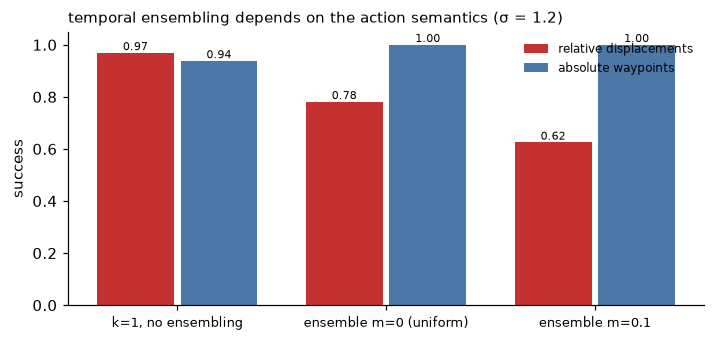

In [25]:
ens = {}
for absolute in (False, True):
    for name, mm in (("k=1, no ensembling", None), ("ensemble m=0 (uniform)", 0.0), ("ensemble m=0.1", 0.1)):
        ens[(absolute, name)] = ChunkedRunner(world, 16, 1, ensemble_m=mm, action_noise=1.2, absolute=absolute, max_steps=60).run(lambda b: m16.sample_actions(b), reach_scen).summary()
        print(f"{'absolute' if absolute else 'relative':8s} {name:22s} {ens[(absolute, name)]}")
names = ["k=1, no ensembling", "ensemble m=0 (uniform)", "ensemble m=0.1"]
plots.grouped_bars({n: {"relative displacements": ens[(False, n)]["success"], "absolute waypoints": ens[(True, n)]["success"]} for n in names}, "success", "temporal ensembling depends on the action semantics (σ = 1.2)", colors=["#c53030", "#4c78a8"])

This is the cleanest lesson of the part. Averaging earlier chunks' predictions is only sensible if those predictions are **still valid** after the robot has moved: an old *absolute waypoint* is; an old *relative displacement* ("move right by 1") is
not once the robot has drifted: ensembling relative actions makes success **worse** than not ensembling at all. With absolute targets, ensembling is at least as good and the robot finishes sooner. (ACT's smoothness claim relies on exactly this:
it predicts target joint positions, and its CVAE decoder's randomness is averaged away by the ensemble.)

## Step 18: The control-rate arithmetic

Putting the measured latencies and the execution schemes together: how fast can the *robot* be commanded? If one model call costs `t` ms and yields `k` executable actions, the sustainable action rate is `k / t` (capped by the robot's own
rate). We use the call latencies measured on this machine (batch 1).

head                                        ms/call  actions/call   sustainable action rate
autoregressive tokens, H=1 (RT-2 style)         3.4             1                    290 Hz
autoregressive tokens, H=16                    47.4            16                    337 Hz
flow matching K=10, H=16                       11.1            16                   1439 Hz
DDIM 10, H=16                                  11.9            16                   1344 Hz
DDPM 100, H=16                                 89.2            16                    179 Hz


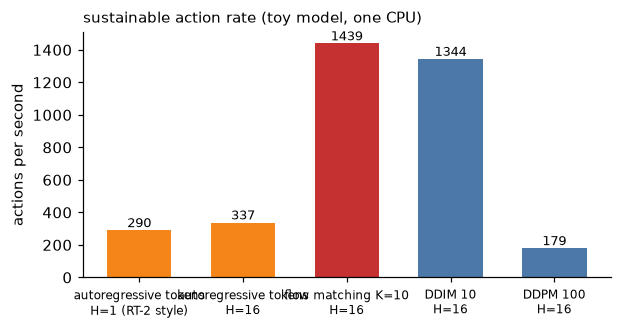

In [26]:
latency = {"autoregressive tokens, H=1 (RT-2 style)": (ms(lambda: ar.generate_cached(one)), 1),
           "autoregressive tokens, H=16": (table["tokens (sampled)"]["ms"], 16),
           "flow matching K=10, H=16": (table["flow matching, K=10"]["ms"], 16),
           "DDIM 10, H=16": (table["diffusion, DDIM 10"]["ms"], 16),
           "DDPM 100, H=16": (table["diffusion, DDPM 100"]["ms"], 16)}
print(f"{'head':42s} {'ms/call':>8s} {'actions/call':>13s} {'sustainable action rate':>25s}")
hz = {}
for name, (t_ms, k) in latency.items():
    hz[name] = effective_control_hz(t_ms, k, control_hz=1e9)
    print(f"{name:42s} {t_ms:8.1f} {k:13d} {hz[name]:22.0f} Hz")
plots.bar_compare({k.replace(", ", "\n"): v for k, v in hz.items()}, "actions per second", "sustainable action rate (toy model, one CPU)", fmt="{:.0f}", colors=["#f58518", "#f58518", "#c53030", "#4c78a8", "#4c78a8"])

The absolute numbers are a tiny model on a laptop; the *ratios* are the lesson. A discrete one-action-per-call head is limited to `1/t` actions per second by its sequential decode (RT-2: 1-5 Hz; OpenVLA: ~6 Hz). Amortising a call over a chunk multiplies the rate by `H`, but only if the call itself stays cheap: a *token* chunk of 32 tokens is barely faster per action than `H = 1` (its decode grows linearly with `H·D`; Step 5 showed the crossover with a 10-step flow head at about 15 tokens), while diffusion's 100 sequential evaluations give the whole gain back. That is why the recent open VLAs (π0, SmolVLA, GR00T) use **chunked continuous heads with ~4-10 evaluations**.

## Step 19: Head-to-head and recap

In [27]:
print(f"{'action head':24s} {'multimodal':>11s} {'unimodal':>9s} {'sequential':>11s} notes")
rows = [("discrete tokens (RT-2)", "yes if sampled", "OK", "H·D", "lossy bins; reuses the VLM unchanged; slow decode"),
        ("regression", "NO (hedges / averages)", "good", "1", "fast; L2 predicts the mean, L1 a median (Step 12)"),
        ("flow matching (π0/GR00T)", "yes", "good", "4-10", "continuous; simple training; few steps"),
        ("diffusion (Diffusion Policy)", "yes (balanced)", "good", "10-100", "DDIM for speed; stochastic chain is slowest")]
for r in rows:
    print(f"{r[0]:24s} {r[1]:>11s} {r[2]:>9s} {r[3]:>11s} {r[4]}")

action head               multimodal  unimodal  sequential notes
discrete tokens (RT-2)   yes if sampled        OK         H·D lossy bins; reuses the VLM unchanged; slow decode
regression               NO (hedges / averages)      good           1 fast; L2 predicts the mean, L1 a median (Step 12)
flow matching (π0/GR00T)         yes      good        4-10 continuous; simple training; few steps
diffusion (Diffusion Policy) yes (balanced)      good      10-100 DDIM for speed; stochastic chain is slowest


```
observation ─► VLM features ─►  discrete tokens  ─► autoregressive decode  H·D sequential calls    lossy bins, multimodal if sampled
                              ├► regression head ─► 1 call                                        averages modes
                              ├► flow matching   ─► K Euler steps (4-10), chunk H                continuous, multimodal, simple loss
                              └► diffusion       ─► DDIM S steps (≈10) or DDPM T steps (100)     continuous, multimodal, stochastic chain
chunk of H actions ─► receding horizon (execute k) │ temporal ensembling (ACT, every step)
```

**Take-aways.** (0) A *regression* head is fastest but cannot represent several valid answers. (1) *Discretisation* lets a pre-trained VLM emit actions with no architectural change, at the price of resolution, `H·D` sequential decoding and a control rate of a few Hz. (2) *Flow matching* and *diffusion* output continuous
chunks and represent several valid solutions; a **one-step** generative head collapses to the mean, so "few steps" has a floor of ~4. (3) *Flow matching's* practical edge is simplicity and well-behaved training, not a dramatic NFE advantage
over DDIM. (4) *Chunking* amortises model calls and shortens the effective horizon; the execution scheme (`k`, ensembling) sets the responsiveness / smoothness / compute trade-off.

### 🧪 Exercises
1. In Step 3 replace the uniform bins by **quantile bins** fitted on the demonstration actions (`ActionBinner.from_quantiles`) and compare the replay error at 16 bins: when do non-uniform bins pay off?
2. Train the autoregressive policy with `temperature` 0.5 instead of 1 or 0 at evaluation (Step 12): how do success and balance move?
3. Add a **third object** to `"go to any"` (`sample_task("any", num_objects=3)`) and check that mode coverage generalises (it counts chunks aimed at objects A/B, extend `mode_coverage`).
4. Repeat Step 15 with the **DDPM policy** instead of flow matching. Does the same `H` trade-off appear?
5. Replace the cosine schedule by the linear one in `DiffusionPolicy` and compare the 4-step DDIM quality: Step 11's SNR plot predicts the difference.